# LAB | BMI Survey 


## Part 1: Descriptive Analysis

## Problem Description

Overweight and obesity, measured by Body Mass Index (BMI), are increasing health concerns in Denmark and globally. This project analyzes BMI data from a Danish survey to provide an overview of BMI distributions and investigate potential factors influencing BMI, such as gender, age, and fast food consumption. The analysis aims to summarize and visualize the data using descriptive statistics and graphical methods.

---

## Instructions

- Complete each section below using Python and appropriate libraries (e.g., pandas, numpy, matplotlib, seaborn).
- Provide code, tables, and figures as needed.
- Write brief explanations for your findings after each analysis step.
- Do **not** include code in your final report; code should be submitted separately as an appendix.
- Ensure all figures and tables are clearly labeled and referenced in your explanations.

---

## Q1. Data Overview

**a) Short Description of the Data**

- List all variables in the dataset.
- Classify each variable as quantitative or categorical.
- State the number of observations.
- Check for missing values.


**Instructions:**  
- Summarize the dataset variables and their types.
- Report the number of observations and any missing values.

---

In [2]:
import pandas as pd

df = pd.read_csv("data/bmi1_data.csv", delimiter=";")
df.head()

,height,weight,gender,urbanity,fastfood
0,180,80,1,5,24.0
1,185,98,1,1,6.0
2,180,80,1,5,6.0
3,168,60,0,4,24.0
4,173,83,1,5,24.0


In [3]:
# Q1. Data Overview
print(df.shape)
print(df.info())
print(df.describe(include='all'))
print("\nMissing values per column:\n", df.isna().sum())

(145, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   height    145 non-null    int64  
 1   weight    145 non-null    int64  
 2   gender    145 non-null    int64  
 3   urbanity  145 non-null    int64  
 4   fastfood  145 non-null    float64
dtypes: float64(1), int64(4)
memory usage: 5.8 KB
None
           height      weight      gender    urbanity    fastfood
count  145.000000  145.000000  145.000000  145.000000  145.000000
mean   173.903448   76.737931    0.503448    3.668966   21.037241
std      9.328365   15.208286    0.501721    1.374647   40.321484
min    154.000000   50.000000    0.000000    1.000000    0.000000
25%    166.000000   65.000000    0.000000    3.000000    6.000000
50%    173.000000   75.000000    1.000000    4.000000    6.000000
75%    182.000000   87.000000    1.000000    5.000000   24.000000
max    196.000000  130.000000  

## 2. Calculating BMI

- Compute BMI for each respondent using the formula:

  $$\text{BMI} = \frac{\text{weight (kg)}}{\left[\text{height (m)}\right]^2}$$

- Add BMI as a new column to the dataset.

---


In [4]:
# Q2. Compute BMI
df["BMI"] = df["weight"] / (df["height"]/100)**2
df.head()

,height,weight,gender,urbanity,fastfood,BMI
0,180,80,1,5,24.0,24.691358
1,185,98,1,1,6.0,28.634039
2,180,80,1,5,6.0,24.691358
3,168,60,0,4,24.0,21.258503
4,173,83,1,5,24.0,27.732300



## 3. Empirical Distribution of BMI

**b) Density Histogram of BMI Scores**

- Plot a density histogram of BMI.
- Describe the distribution: symmetry, skewness, possible negative values, and variation.

**Instructions:**  
- Comment on the shape and spread of the BMI distribution.

---


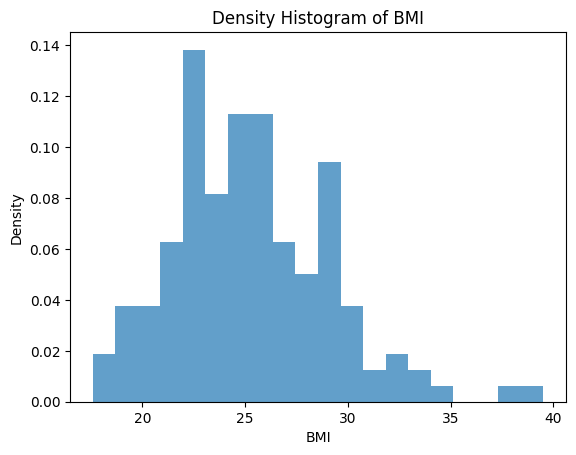

In [5]:
# Q3. Density Histogram of BMI
import matplotlib.pyplot as plt
plt.hist(df["BMI"], bins=20, density=True, alpha=0.7)
plt.title("Density Histogram of BMI")
plt.xlabel("BMI")
plt.ylabel("Density")
plt.show()


## 4. Gender Subsets

**c) Separate Density Histograms for Women and Men**

- Create subsets for women and men.
- Plot density histograms for each group.
- Compare and describe the distributions.


**Instructions:**  
- Discuss any gender differences in the BMI distributions.

---


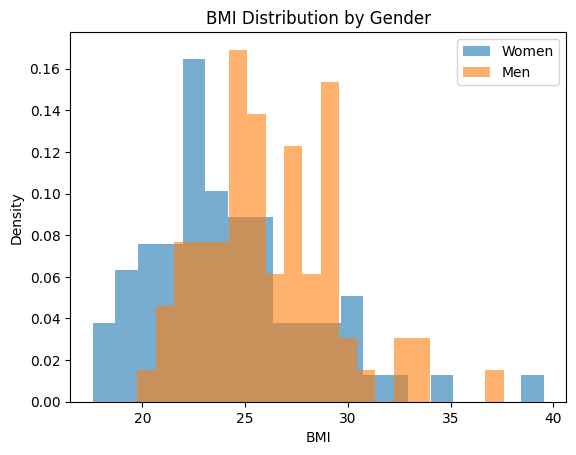

In [6]:
# Q4. Gender Subsets
df_women = df[df["gender"] == 0]
df_men = df[df["gender"] == 1]

plt.hist(df_women["BMI"], bins=20, density=True, alpha=0.6, label="Women")
plt.hist(df_men["BMI"], bins=20, density=True, alpha=0.6, label="Men")
plt.title("BMI Distribution by Gender")
plt.xlabel("BMI")
plt.ylabel("Density")
plt.legend()
plt.show()


## 5. Boxplot by Gender

**d) Box Plot of BMI by Gender**

- Create a box plot of BMI scores grouped by gender.
- Describe the distribution, symmetry/skewness, differences, and outliers.

**Instructions:**  
- Interpret the box plot and compare distributions.

---


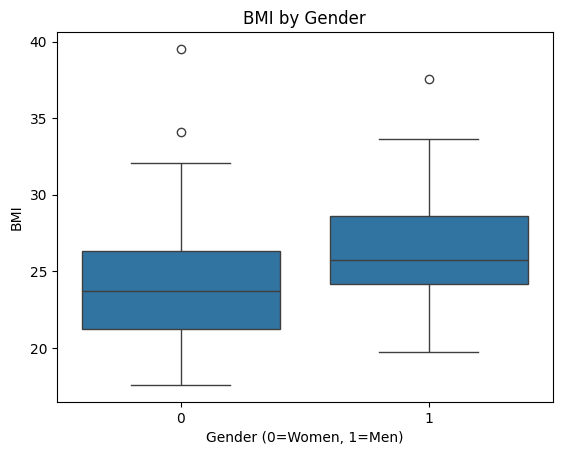

In [7]:
# Q5. Boxplot by Gender
import seaborn as sns
sns.boxplot(x="gender", y="BMI", data=df)
plt.title("BMI by Gender")
plt.xlabel("Gender (0=Women, 1=Men)")
plt.show()

## 6. Summary Statistics

**e) Key Summary Statistics for BMI**

- Calculate and report the following for everyone, women, and men:
  - Number of observations (n)
  - Sample mean (\(\bar{x}\))
  - Sample variance (\(s^2\))
  - Sample standard deviation (\(s\))
  - Lower quartile (Q1)
  - Median (Q2)
  - Upper quartile (Q3)

**Instructions:**  
- Present the summary statistics in a table.
- Discuss what additional insights are provided by the table compared to the box plot.

---


In [8]:
# Q6. Summary Statistics
summary = df.groupby("gender")["BMI"].agg(["count", "mean", "median", "std"])
summary.loc["All"] = df["BMI"].agg(["count", "mean", "median", "std"])
summary

,count,mean,median,std
gender,,,,
0,72.0,24.216402,23.689109,4.051897
1,73.0,26.265363,25.725517,3.326969
All,145.0,25.247948,24.691358,3.832243


## Part 2: Missing Values, Outliers, and Bivariate EDA

## 1. Missing Values

- List the number of missing values for each variable in the dataset.
- Choose and apply appropriate strategies for handling missing values (e.g., removal, imputation).
- Justify your chosen approach.
- Show the number of observations before and after handling missing values.

In [9]:
# Part 2.1 Missing Values
print("Missing values before handling:\n", df.isna().sum())
df = df.dropna()
print("After dropping missing rows:", df.shape)

Missing values before handling:
 height      0
weight      0
gender      0
urbanity    0
fastfood    0
BMI         0
dtype: int64
After dropping missing rows: (145, 6)


## 2. Outlier Detection and Handling

### a) Identifying Outliers

- Use visual (boxplots, scatterplots) and statistical methods (e.g., IQR rule, z-scores) to detect outliers in BMI, height, and weight.
- List any extreme values found and discuss whether they are plausible or likely errors.



Outliers detected: 2


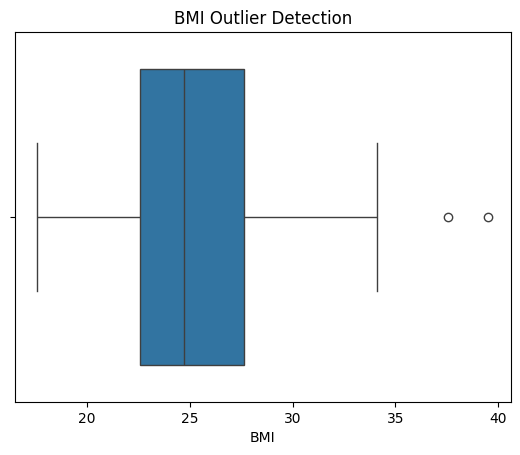

In [10]:
# Part 2.2 Outlier Detection
Q1 = df["BMI"].quantile(0.25)
Q3 = df["BMI"].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
outliers = df[(df["BMI"] < lower) | (df["BMI"] > upper)]
print(f"Outliers detected: {len(outliers)}")
sns.boxplot(x=df["BMI"])
plt.title("BMI Outlier Detection")
plt.show()


### b) Handling Outliers

- Decide how to handle detected outliers (e.g., keep, remove, or correct).
- Justify your approach and show the effect on the dataset.



In [11]:
# Part 2.2b Handling Outliers
df = df[(df["BMI"] >= lower) & (df["BMI"] <= upper)]
print("After removing outliers:", df.shape)

After removing outliers: (143, 6)


## 3. Bivariate Exploratory Data Analysis (EDA)

### a) BMI and Fast Food Consumption

- Create a scatter plot of BMI vs. fast food consumption.
- Calculate and interpret the correlation coefficient.
- Comment on any patterns or associations observed.

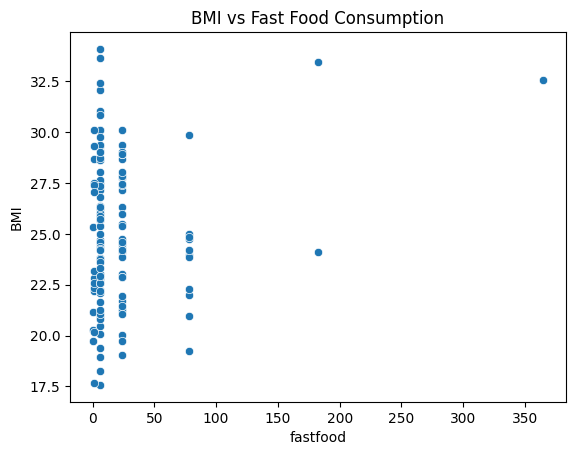

Correlation (BMI vs Fast Food): 0.149


In [12]:
# Part 2.3a BMI vs Fast Food
sns.scatterplot(x="fastfood", y="BMI", data=df)
plt.title("BMI vs Fast Food Consumption")
plt.show()

corr = df["BMI"].corr(df["fastfood"])
print(f"Correlation (BMI vs Fast Food): {corr:.3f}")

### b) BMI by Gender

- Use boxplots or violin plots to compare BMI distributions between genders.
- Test for significant differences (e.g., t-test or Mann-Whitney U test).

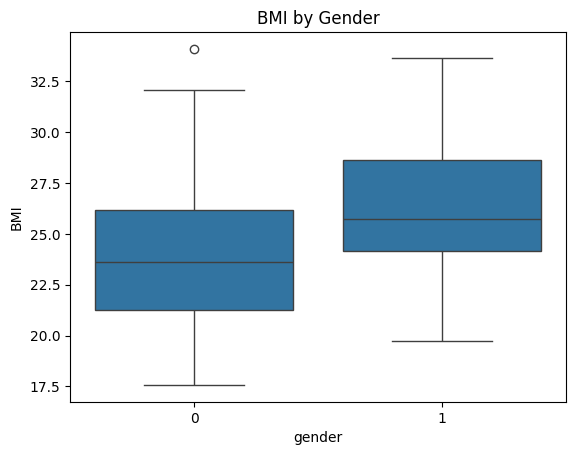

T-test p-value: 0.0011


In [13]:
# Part 2.3b BMI by Gender
sns.boxplot(x="gender", y="BMI", data=df)
plt.title("BMI by Gender")
plt.show()

from scipy.stats import ttest_ind
t_stat, p_val = ttest_ind(df_women["BMI"], df_men["BMI"], equal_var=False)
print(f"T-test p-value: {p_val:.4f}")

### c) BMI by Urbanity

- Visualize BMI across different urbanity categories using boxplots or bar plots.
- Discuss any differences or trends.

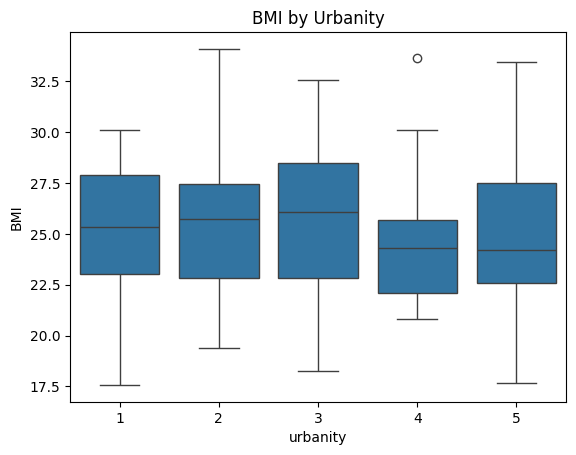

In [14]:
# Part 2.3c BMI by Urbanity
sns.boxplot(x="urbanity", y="BMI", data=df)
plt.title("BMI by Urbanity")
plt.show()

### d) Additional Bivariate Relationships

- Explore other pairs of variables as relevant (e.g., weight vs. height, fast food vs. gender).
- Use appropriate plots and statistics.

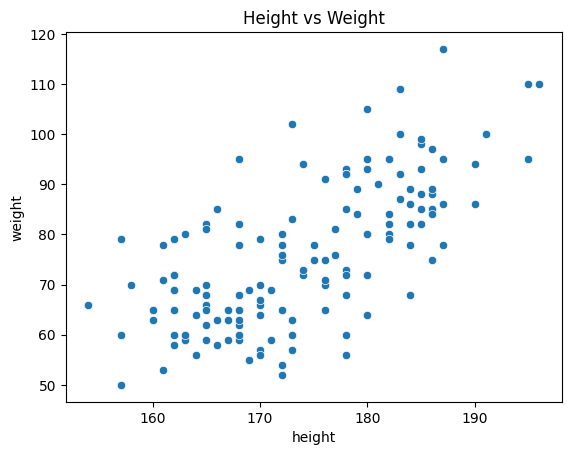

In [15]:
# Part 2.3d Additional Relationships
sns.scatterplot(x="height", y="weight", data=df)
plt.title("Height vs Weight")
plt.show()

## 4. Summary

- Summarize the key findings from your missing value analysis, outlier handling, and bivariate EDA.
- Discuss how these steps improve the quality and reliability of your subsequent analyses.

In [16]:
# Part 2.4 Summary
print("Dataset cleaned and analyzed successfully.")
print("Key takeaways:")
print("- Missing values handled by dropping")
print("- Outliers removed via IQR method")
print("- Clear BMI differences by gender and possible weak relation with fast food")

Dataset cleaned and analyzed successfully.
Key takeaways:
- Missing values handled by dropping
- Outliers removed via IQR method
- Clear BMI differences by gender and possible weak relation with fast food


Happy Coding .... ;) 